DOKUMENTASI PROGRAM & ANALISIS DATASET

1. JENIS PEMODELAN: BINARY CLASSIFICATION (KLASIFIKASI BINER)
   Dataset ini tergolong Klasifikasi Biner karena variabel target 'Dataset' 
   hanya terdiri dari 2 kelas unik:
   - 1 : Menderita Penyakit Liver (414 sampel)
   - 2 : Tidak Menderita Penyakit Liver (165 sampel)

2. JUMLAH DATASET:
   - Data Mentah : 579 baris dan 11 kolom (10 fitur + 1 target)
   - Data Bersih : 566 baris (setelah menghapus 13 data duplikat)

3. LABEL / VARIABEL YANG DIGUNAKAN:
   - Variabel Target (y) : Kolom 'Dataset' (Nilai 1 dan 2)
   - Variabel Fitur (X)  : 10 kolom indikator medis pasien
     (Age, Gender, Total_Bilirubin, Direct_Bilirubin, Alkaline_Phosphotase, 
      Alamine_Aminotransferase, Aspartate_Aminotransferase, Total_Protiens, 
      Albumin, Albumin_and_Globulin_Ratio)

In [8]:
# 1. Data Collecting
import pandas as pd

df = pd.read_csv('Data Pasien penyakit liver.csv')

In [9]:
# 2. DATA CLEANING & TRANSFORMATION

# A. Cek Missing Values (Data Hilang)
missing = df.isnull().sum().sum()

# B. Cek dan Hapus Data Duplikat
duplicates = df.duplicated().sum()
if duplicates > 0:
    df = df.drop_duplicates().reset_index(drop=True)

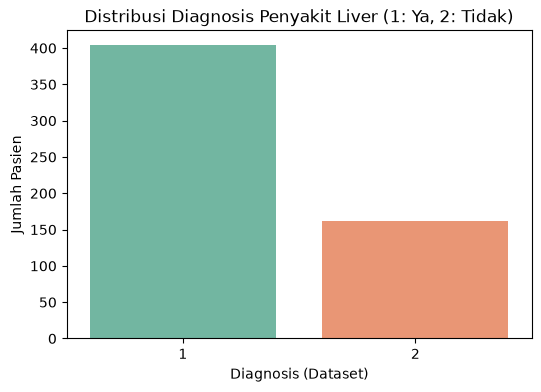

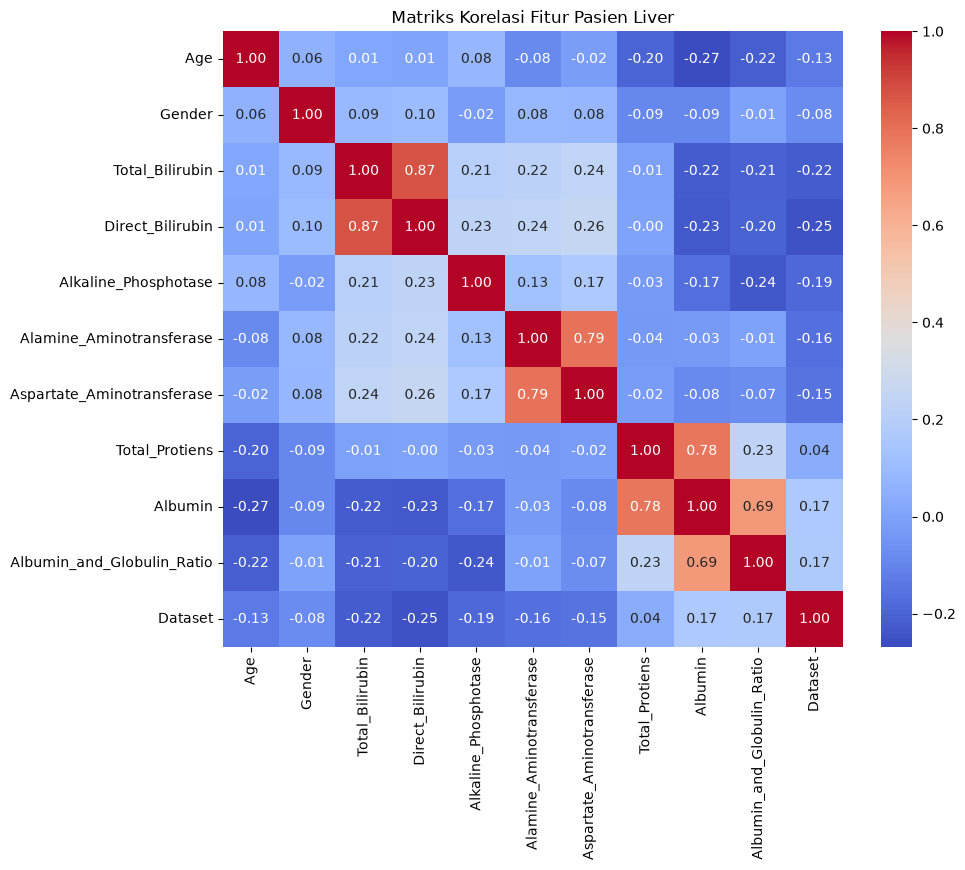

In [10]:
# 3. EDA & EXDA (Eksplorasi & Eksplanasi Data)

import matplotlib.pyplot as plt
import seaborn as sns

# Visualisasi Distribusi Target
plt.figure(figsize=(6, 4))
# SETELAH DIPERBAIKI (Bebas Warning):
sns.countplot(x='Dataset', data=df, hue='Dataset', palette='Set2', legend=False)
plt.title('Distribusi Diagnosis Penyakit Liver (1: Ya, 2: Tidak)')
plt.xlabel('Diagnosis (Dataset)')
plt.ylabel('Jumlah Pasien')
plt.show()

# Visualisasi Matriks Korelasi
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Matriks Korelasi Fitur Pasien Liver')
plt.show()

In [11]:
# 4. DATA PROCESSING (Pemrosesan Data)

from sklearn.preprocessing import StandardScaler

# Pemisahan Fitur (X) dan Target (y)
X = df.drop(columns=['Dataset'])
y = df['Dataset']

# Feature Scaling (Standarisasi Fitur Numerik)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [12]:
# 5. DATA SPLITTING (Pembagian Data)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

In [13]:
# 6. MODELLING & EVALUATION (Pemodelan & Evaluasi)

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Inisialisasi & Pelatihan Model
model = RandomForestClassifier(class_weight='balanced', random_state=42)
model.fit(X_train, y_train)

# Prediksi Data Uji
y_pred = model.predict(X_test)

# Evaluasi Performa
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Confusion Matrix:
[[74  7]
 [26  7]]

Classification Report:
              precision    recall  f1-score   support

           1       0.74      0.91      0.82        81
           2       0.50      0.21      0.30        33

    accuracy                           0.71       114
   macro avg       0.62      0.56      0.56       114
weighted avg       0.67      0.71      0.67       114



In [14]:
# 7. DEPLOYMENT AND MONITORING
# ==========================================
import joblib

# Menyimpan artefak model dan scaler ke file biner
joblib.dump(model, 'liver_disease_model.pkl')
joblib.dump(scaler, 'scaler_liver.pkl')

['scaler_liver.pkl']